In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import matplotlib.patches as patches


fontsize = 7
plt.rcParams.update({
    'font.family': 'Arial',     # or 'Helvetica' if embedded properly
    'font.size': fontsize,
    'pdf.fonttype': 42,         # Embed TrueType (for editable text)
    'ps.fonttype': 42,
    'axes.labelsize': fontsize,
    'xtick.labelsize': fontsize,
    'ytick.labelsize': fontsize,
    'axes.facecolor': 'None',   # transparent background if needed
    'axes.edgecolor': 'black',
    'axes.linewidth': 0.5
})


blue = '#1E88E5'
red = '#FF1D25'

dir0 = "../"
dir1 = dir0+'data/'
dirf = dir0+'figures/'

## Fig. 2A

/var/folders/v8/_5pczj3j1hxcfl8_d87gmyt80000gn/T/ipykernel_50479/1110326991.py:30: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.arrow( -0.3, 0.3, 0.6, -0.6, length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', color='black', facecolor='green')


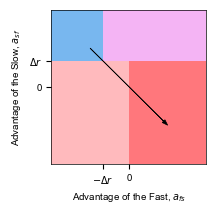

In [ ]:

aplot = 10 + np.arange(21)
fig, ax = plt.subplots( figsize=(2.,2.))
        
ax.set_xlabel('Advantage of the Fast, 'r'$a_{fs}$')
ax.set_ylabel('Advantage of the Slow, 'r'$a_{sf}$')

ax.set_yticks([0, 0.2]); ax.set_yticklabels([0, r'$\Delta r$'])
ax.set_xticks([-0.2, 0]); ax.set_xticklabels([r'$-\Delta r$', 0])

# Create a rectangle: (x, y), width, height
rect = patches.Rectangle((-0.6, 0.2), 0.4, 0.4, edgecolor='none', facecolor=blue, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.6, -0.6), 0.6, 0.8, edgecolor='none', facecolor=red, alpha=0.3)
ax.add_patch(rect)
rect = patches.Rectangle((0.0, -0.6), 0.6, 0.8, edgecolor='none', facecolor=red, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, 0.2), 0.8, 0.4, edgecolor='none', facecolor='violet', alpha=0.6)
ax.add_patch(rect)
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(-0.6, 0.6)


ax.arrow( -0.3, 0.3, 0.6, -0.6, length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', color='black', facecolor='green')

fig.savefig(dirf + 'Fig2/2a_PD.pdf', bbox_inches='tight', transparent=True)

In [ ]:
import pandas as pd, numpy as np
S = lambda m: pd.read_csv(dir1 + f"{m}/summary.csv").assign(label=lambda d: d["label"].fillna(""))

def theory(afs, asf, dr, D=1.0):        # returns (u or u_ms, u_mf)
    if afs > -dr and asf > dr:
        A = afs + asf
        ums = 2*np.sqrt(D*asf*(dr+afs)/A) if afs <= 0 else 2*np.sqrt(D*(dr+afs))
        return ums, 2*np.sqrt(D*(asf-dr))
    if asf > dr:
        return -2*np.sqrt(D*(asf-dr)), np.nan
    return 2*np.sqrt(D*max(dr, dr+afs)), np.nan

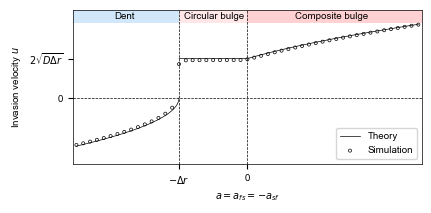

In [ ]:
fig, ax = plt.subplots(figsize=(4.5, 2))

rect = patches.Rectangle((-0.55, 1.7), 0.35, 2, edgecolor='none', facecolor=blue, alpha=0.2)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, 1.7), 0.2, 2, edgecolor='none', facecolor=red, alpha=0.1)
ax.add_patch(rect)
rect = patches.Rectangle((0.0, 1.7), 0.6, 2, edgecolor='none', facecolor=red, alpha=0.2)
ax.add_patch(rect)

a = S("fig2a").sort_values("afs")

a = S("fig2a").sort_values("afs")
dr = (a.rf - a.rs).iloc[0]; D = a.D.iloc[0]
A = np.linspace(-0.5, 0.5, 2001)                    # dense grid for the curve
u_th = np.where(A < -dr,
                -2*np.sqrt(D*np.clip(-A - dr, 0, None)),      # dent
                 2*np.sqrt(D*np.maximum(dr, A + dr)))         # circular / composite bulge
m = A < -dr                                          # plot the two sides separately so the
plt.plot(A[m],  u_th[m],  "k-", lw=0.5, label='Theory')                      # jump at a = -dr is not drawn as a
plt.plot(A[~m], u_th[~m], "k-", lw=0.5)                      # vertical line
ax.scatter(a.afs, a.u_late, color='none', edgecolor='k', s=5, linewidth=0.5, label='Simulation')
ax.set_xticks([-0.2, 0.])
ax.set_xticklabels([r'$-\Delta r$',0])
ax.set_xlabel(r'$a=a_{fs}=-a_{sf}$')
ax.axhline(0, color='k', lw=0.5, ls='--')
ax.axvline(0, color='k', lw=0.5, ls='--')
ax.axvline(-0.2, color='k', lw=0.5, ls='--')
ax.set_yticks([0, 2*(1*0.2)**0.5])
ax.set_yticklabels([0, r'$2\sqrt{D\Delta r}$'])
ax.set_ylabel(r'Invasion velocity $u$')
ax.legend(loc='lower right')
ax.set_xlim(-0.51, 0.51)
ax.set_ylim(-1.5, 2.0)
#ax.set_title('Anti-symmetric interactions')
ax.text(-0.39, 1.8,'Dent')
ax.text(-0.185, 1.8,'Circular bulge')
ax.text(0.14, 1.8,'Composite bulge')

fig.savefig(dirf + 'Fig2/2b_plot.pdf', bbox_inches='tight', transparent=True)

## Fig. 2B

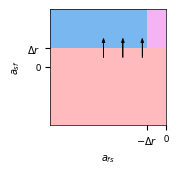

In [ ]:

aplot = 10 + np.arange(21)
fig, ax = plt.subplots( figsize=(1.5,1.5))
        
ax.set_xlabel(r'$a_{fs}$')
ax.set_ylabel(r'$a_{sf}$')

ax.set_yticks([0, 0.2]); ax.set_yticklabels([0, r'$\Delta r$'])
ax.set_xticks([-0.2, 0]); ax.set_xticklabels([r'$-\Delta r$', 0])

# Create a rectangle: (x, y), width, height
rect = patches.Rectangle((-4, 0.2), 3.8, 0.4, edgecolor='none', facecolor=blue, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-4, -0.6), 4.0, 0.8, edgecolor='none', facecolor=red, alpha=0.3)
ax.add_patch(rect)
rect = patches.Rectangle((0.0, -0.6), 0.6, 0.8, edgecolor='none', facecolor=red, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, 0.2), 0.8, 0.4, edgecolor='none', facecolor='violet', alpha=0.6)
ax.add_patch(rect)
ax.set_xlim(-1.2, 0.)
ax.set_ylim(-0.6, 0.6)


ax.arrow( -0.25, 0.1, 0, 0.2, length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')
ax.arrow( -0.45, 0.1, 0, 0.2, length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')
ax.arrow( -0.65, 0.1, 0, 0.2, length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')
fig.savefig(dirf + 'Fig2/2b_PD.pdf', bbox_inches='tight', transparent=True)

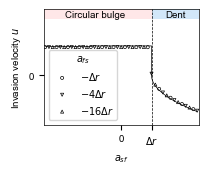

In [ ]:
fig, ax = plt.subplots(figsize=(2,1.5))
rect = patches.Rectangle((0.2, 1.7), 0.35, 2, edgecolor='none', facecolor=blue, alpha=0.2)
ax.add_patch(rect)
rect = patches.Rectangle((-0.55, 1.7), 0.75, 2, edgecolor='none', facecolor=red, alpha=0.1)
ax.add_patch(rect)

for i, s in enumerate( S("fig2b").groupby("label")):
    lab, g = s
    g = g.sort_values("asf")
    inds = (np.arange(len(g.asf.values)) % 3 == i)
    ax.scatter(np.array(g.asf.values[inds]), np.array(g.u_late.values[inds]), s=5, color='none', edgecolor='k', marker=['o','v','^'][i], lw=0.5, label=[r'$-\Delta r$',r'$-4\Delta r$',r'$-16\Delta r$'][i])

ax.text(-0.37, 1.75,'Circular bulge')
ax.text(0.29, 1.75,'Dent')
ax.set_yticks([0])

A = np.linspace(-0.5, 0.5, 2001)                    # dense grid for the curve
u_th = np.where(A > dr,
                -2*np.sqrt(D*np.clip(A - dr, 0, None)),      # dent
                 2*np.sqrt(D*np.maximum(dr, A )))         # circular / composite bulge
m = A > -dr                                          # plot the two sides separately so the
plt.plot(A[m],  u_th[m],  "k-", lw=0.5)                      # jump at a = -dr is not drawn as a
plt.plot(A[~m], u_th[~m], "k-", lw=0.5)                      # vertical line

ax.axvline(0.2, color='k', lw=0.5, ls='--')

ax.set_xlabel(r'$a_{sf}$')
ax.set_ylabel(r'Invasion velocity $u$')
ax.set_xticks([ 0., 0.2])
ax.set_xticklabels([0, r'$\Delta r$'])
ax.legend(title=r'$a_{fs}$', loc = 'lower left')
ax.set_xlim(-0.51, 0.51)
ax.set_ylim(-1.5, 2.0)

fig.savefig(dirf + 'Fig2/2c_plot.pdf', bbox_inches='tight', transparent=True)

## Fig. 2C

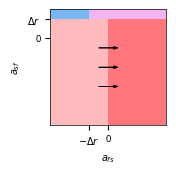

In [ ]:

aplot = 10 + np.arange(21)
fig, ax = plt.subplots( figsize=(1.5,1.5))
        
ax.set_xlabel(r'$a_{fs}$')
ax.set_ylabel(r'$a_{sf}$')
ax.set_yticks([0, 0.2]); ax.set_yticklabels([0, r'$\Delta r$'])
ax.set_xticks([-0.2, 0]); ax.set_xticklabels([r'$-\Delta r$', 0])

# Create a rectangle: (x, y), width, height
rect = patches.Rectangle((-4, 0.2), 3.8, 0.4, edgecolor='none', facecolor=blue, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-4, -2.6), 4.0, 2.8, edgecolor='none', facecolor=red, alpha=0.3)
ax.add_patch(rect)
rect = patches.Rectangle((0.0, -2.6), 0.6, 2.8, edgecolor='none', facecolor=red, alpha=0.6)
ax.add_patch(rect)
rect = patches.Rectangle((-0.2, 0.2), 0.8, 0.4, edgecolor='none', facecolor='violet', alpha=0.6)
ax.add_patch(rect)
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(-0.9, 0.3)


ax.arrow( -0.1, -0.1, 0.2, 0., length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')
ax.arrow( -0.1, -0.3, 0.2, 0., length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')
ax.arrow( -0.1, -0.5, 0.2, 0., length_includes_head=True, head_width=0.03, linewidth=0.5, shape='full', facecolor='black')

fig.savefig(dirf + 'Fig2/2c_PD.pdf', bbox_inches='tight', transparent=True)

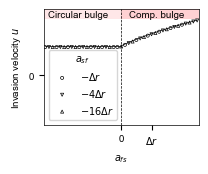

In [ ]:
fig, ax = plt.subplots(figsize=(2,1.5))
rect = patches.Rectangle((-0.55, 1.7), 0.55, 2, edgecolor='none', facecolor=red, alpha=0.1)
ax.add_patch(rect)
rect = patches.Rectangle((0.0, 1.7), 0.55, 2, edgecolor='none', facecolor=red, alpha=0.2)
ax.add_patch(rect)

for i, s in enumerate( S("fig2c").groupby("label")):
    lab, g = s
    g = g.sort_values("asf")
    inds = (np.arange(len(g.asf.values)) % 3 == i)
    ax.scatter(np.array(g.afs.values[inds]), np.array(g.u_late.values[inds]), s=5, color='none', edgecolor='k', marker=['o','v','^'][i], lw=0.5, label=[r'$-\Delta r$',r'$-4\Delta r$',r'$-16\Delta r$'][i])


ax.text(-0.48, 1.75,'Circular bulge')
ax.text(0.05, 1.75,'Comp. bulge')
ax.set_yticks([0])

A = np.linspace(-0.5, 0.5, 2001)                    # dense grid for the curve
u_th = np.where(A > -10,
                 2*np.sqrt(D*np.maximum(dr, A+dr )),      # dent
                 2*np.sqrt(D*np.maximum(dr, A+dr )))         # circular / composite bulge
m = A > 0                                         # plot the two sides separately so the
plt.plot(A[m],  u_th[m],  "k-", lw=0.5)                      # jump at a = -dr is not drawn as a
plt.plot(A[~m], u_th[~m], "k-", lw=0.5)                      # vertical line

ax.axvline(0., color='k', lw=0.5, ls='--')

ax.set_xlabel(r'$a_{fs}$')
ax.set_ylabel(r'Invasion velocity $u$')
ax.set_xticks([ 0., 0.2])
ax.set_xticklabels([0, r'$\Delta r$'])
ax.legend(title=r'$a_{sf}$', loc = 'lower left')
ax.set_xlim(-0.51, 0.51)
ax.set_ylim(-1.5, 2.0)

fig.savefig(dirf + 'Fig2/2d_plot.pdf', bbox_inches='tight', transparent=True)